# 02 · Correlation through regimes

Did Bitcoin become more equity-sensitive, and how stable is that relationship?

Run this notebook from top to bottom. It is independent of the execution state of other notebooks.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from btc_nasdaq.config import project_root, load_config
from btc_nasdaq.research import research_context, run_period
from btc_nasdaq.plotting import set_theme, save_figure, shade_holdout, PALETTE
from btc_nasdaq.data import sha256

set_theme()
pd.options.display.float_format = "{:,.4f}".format
ROOT = project_root()
c = research_context(ROOT)
cfg, prices, returns = c["cfg"], c["prices"], c["returns"]
betas, beta, signal = c["betas"], c["beta"], c["signal"]
HOLDOUT = cfg["validation"]["holdout_start"]
summary_path = ROOT / "reports/tables/summary.json"
if not summary_path.exists():
    raise RuntimeError("Run uv run python scripts/run_research.py before executing the notebooks.")
run_record = json.loads(summary_path.read_text())
if (run_record["config_sha256"] != sha256(ROOT / "configs/research.toml") or
    run_record["data_sha256"] != sha256(ROOT / "data/processed/aligned_prices.parquet")):
    raise RuntimeError("Summary tables are stale. Re-run scripts/run_research.py.")
display(Markdown(f"**Data:** {prices.index.min():%Y-%m-%d} to {prices.index.max():%Y-%m-%d} "
                 f"· **{len(prices):,} synchronized sessions** · BTC-USD / QQQ · "
                 f"**Fixed baseline:** {cfg['strategy']['model']}"))

**Data:** 2018-01-02 to 2026-11-06 · **2,225 synchronized sessions** · BTC-USD / QQQ · **Fixed baseline:** ewma_63

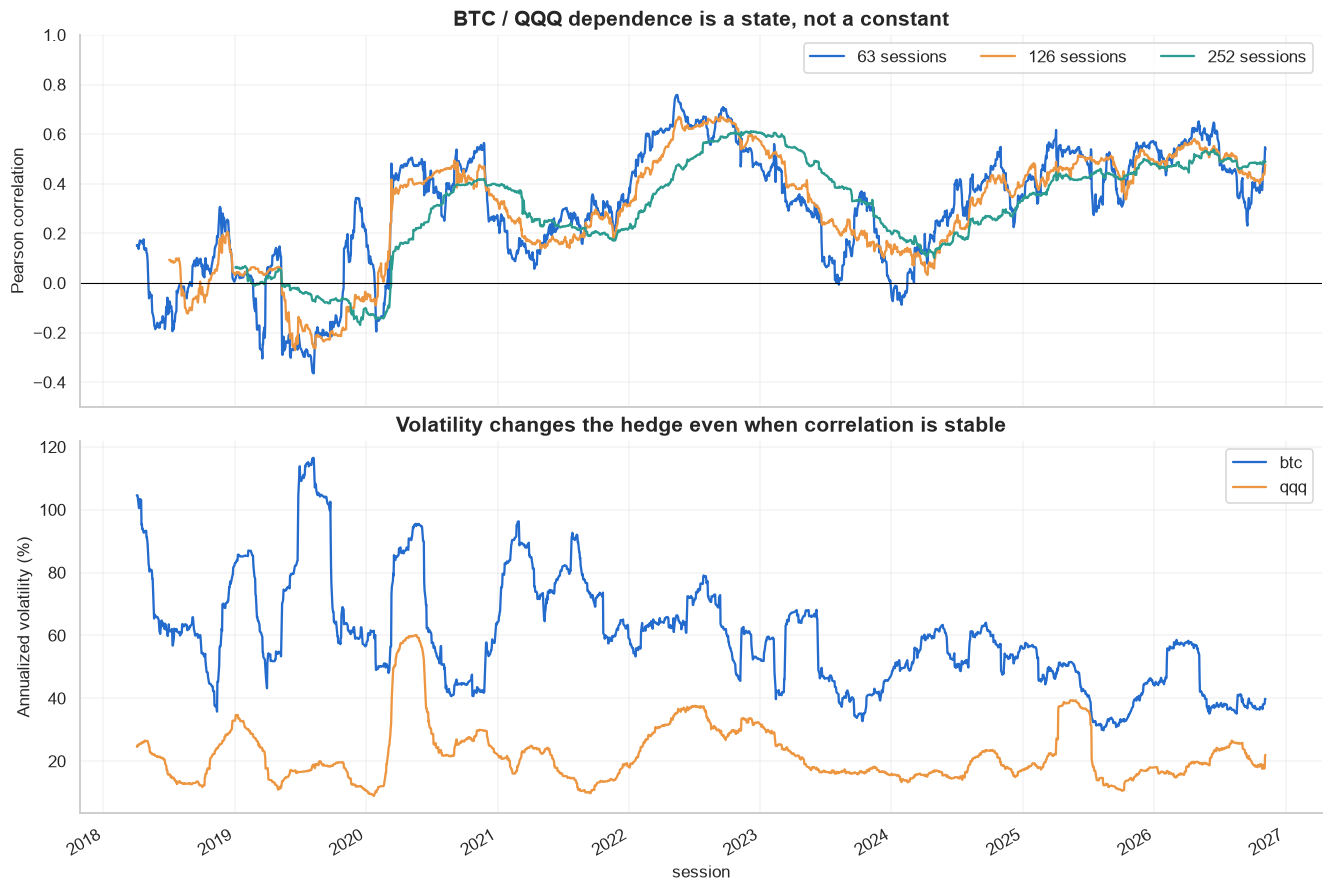

,n,correlation,spearman,beta,btc_vol,qqq_vol
year,,,,,,
2018,250,0.0596,0.0269,0.2040,0.7831,0.2287
2019,252,-0.1010,0.0120,-0.4728,0.7581,0.1619
2020,253,0.3933,0.3107,0.7245,0.6565,0.3563
2021,252,0.2177,0.2466,0.9047,0.7571,0.1822
2022,251,0.6058,0.6143,1.1802,0.6264,0.3215
2023,250,0.2114,0.2573,0.5967,0.5043,0.1787
2024,252,0.3310,0.2984,1.0461,0.5691,0.1801
2025,250,0.4801,0.4620,0.8465,0.4160,0.2360
2026,214,0.4881,0.4957,0.9851,0.4427,0.2194


In [2]:
from btc_nasdaq.diagnostics import regime_summary, block_bootstrap
regimes = regime_summary(returns)
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
for window in [63, 126, 252]:
    returns.btc.rolling(window).corr(returns.qqq).plot(ax=axes[0], label=f"{window} sessions")
axes[0].axhline(0, color="black", lw=.7)
axes[0].set(title="BTC / QQQ dependence is a state, not a constant", ylabel="Pearson correlation", ylim=(-.5, 1))
axes[0].legend(ncol=3)
returns.rolling(63).std().mul(np.sqrt(252)*100).plot(ax=axes[1])
axes[1].set(title="Volatility changes the hedge even when correlation is stable", ylabel="Annualized volatility (%)")
save_figure(fig, ROOT, "02_correlation_and_volatility")
plt.show()
display(regimes)

## How uncertain are annual correlations?

The bands below resample paired returns in circular 10-session blocks. This retains short-run
dependence and both legs' joint observations. It is a descriptive confidence interval, not proof
that the next year's correlation lies inside the band. A partial final year is identified by `n`.

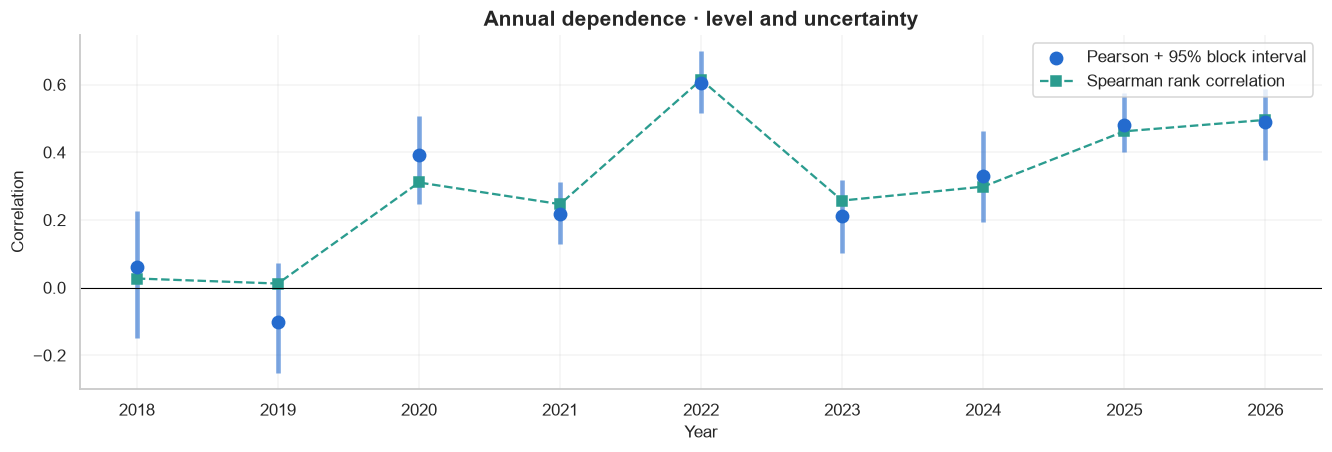

In [3]:
intervals = []
for year, sample in returns.groupby(returns.index.year):
    draws = block_bootstrap(sample[["btc", "qqq"]].to_numpy(),
                           lambda a: np.corrcoef(a.T)[0, 1], samples=500, block=10, seed=42)
    intervals.append(np.quantile(draws, [.025, .975]))
intervals = np.array(intervals)
fig, ax = plt.subplots(figsize=(12, 4))
ax.vlines(regimes.index, intervals[:, 0], intervals[:, 1], color=PALETTE[0], lw=3, alpha=.6)
ax.scatter(regimes.index, regimes.correlation, s=65, color=PALETTE[0], zorder=3, label="Pearson + 95% block interval")
ax.plot(regimes.index, regimes.spearman, "s--", color=PALETTE[2], label="Spearman rank correlation")
ax.axhline(0, color="black", lw=.7)
ax.set(title="Annual dependence · level and uncertainty", ylabel="Correlation", xlabel="Year", xticks=regimes.index)
ax.legend()
plt.show()

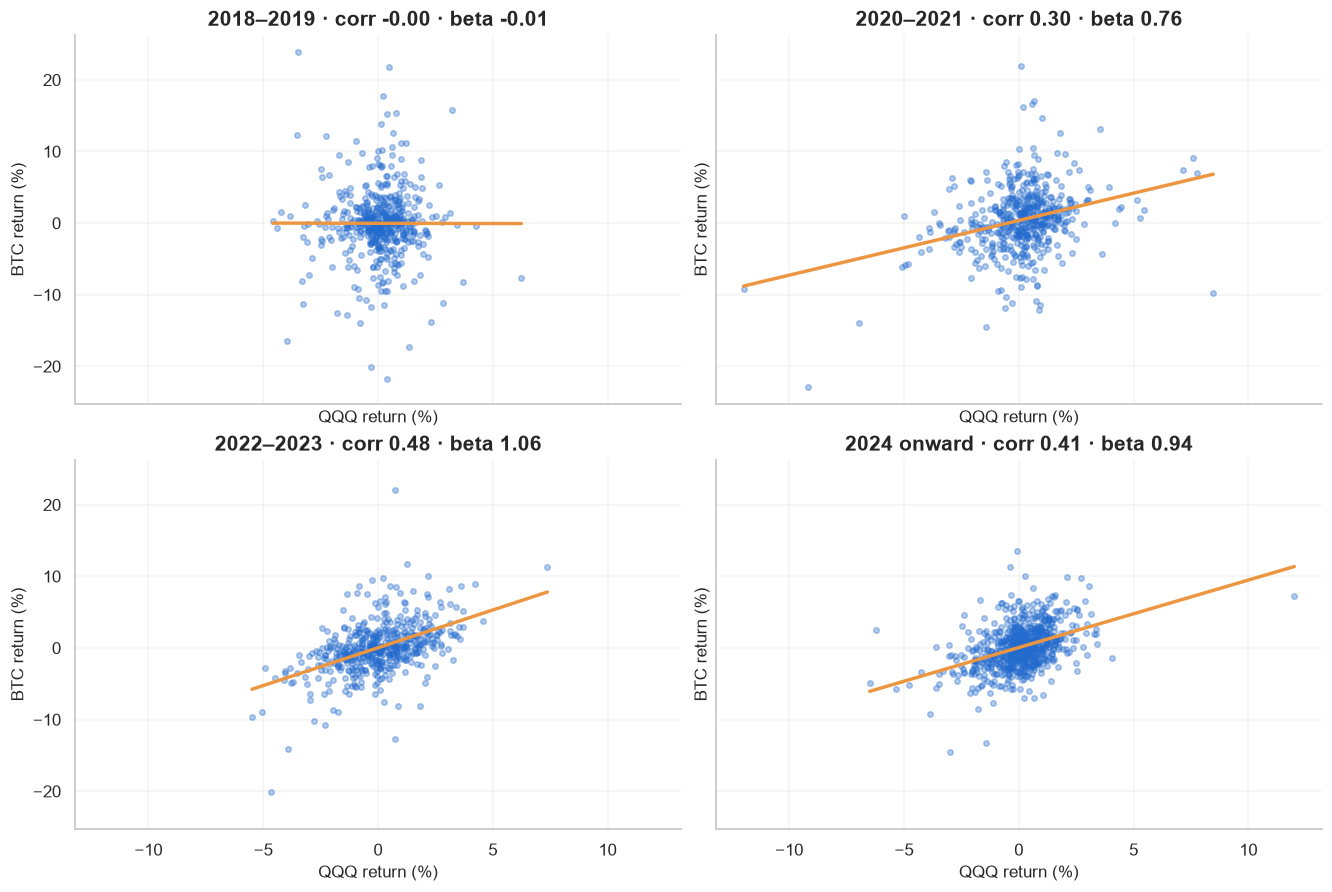

In [4]:
eras = {"2018–2019": returns.loc[:"2019"], "2020–2021": returns.loc["2020":"2021"],
        "2022–2023": returns.loc["2022":"2023"], "2024 onward": returns.loc[HOLDOUT:]}
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True, sharey=True)
for ax, (name, sample) in zip(axes.flat, eras.items()):
    sns.regplot(x=sample.qqq*100, y=sample.btc*100, ax=ax, ci=None,
                scatter_kws={"s": 13, "alpha": .35}, line_kws={"color": PALETTE[1]})
    b = sample.btc.cov(sample.qqq) / sample.qqq.var()
    ax.set(title=f"{name} · corr {sample.btc.corr(sample.qqq):.2f} · beta {b:.2f}",
           xlabel="QQQ return (%)", ylabel="BTC return (%)")
save_figure(fig, ROOT, "02_regime_scatter")
plt.show()

## Conditional and lead/lag diagnostics

Contemporaneous conditioning below uses training-period QQQ volatility and return thresholds.
It describes realized market states; it is not a forecast. Lead/lag scans are exploratory multiple
comparisons. A peak at a lag is not an executable edge without a separate delayed test.

,n,correlation,beta
All,"2,224.0000",0.2915,0.7704
QQQ negative,977.0000,0.2814,0.9404
QQQ worst train decile,239.0000,0.3280,1.2520
High trailing QQQ vol,562.0000,0.4129,0.7912


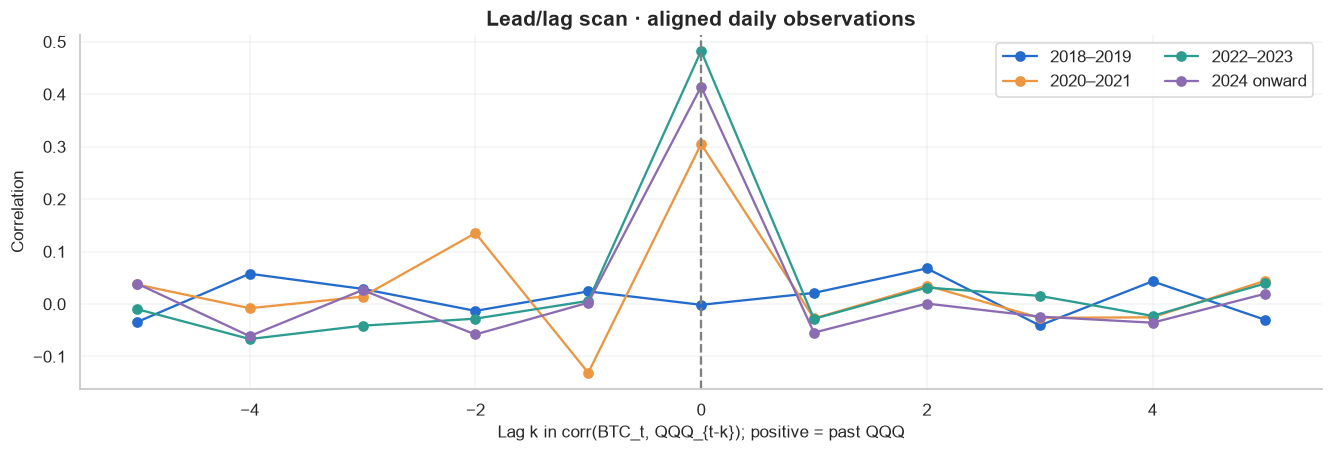

In [5]:
train = returns.loc[:cfg["validation"]["train_end"]]
vol = returns.qqq.rolling(21).std()
vol_cutoff = vol.loc[:cfg["validation"]["train_end"]].quantile(.75)
down_cutoff = train.qqq.quantile(.1)
subsets = {"All": returns, "QQQ negative": returns.loc[returns.qqq < 0],
           "QQQ worst train decile": returns.loc[returns.qqq < down_cutoff],
           "High trailing QQQ vol": returns.loc[vol > vol_cutoff]}
conditional = pd.DataFrame({name: {"n": len(v), "correlation": v.btc.corr(v.qqq),
                                  "beta": v.btc.cov(v.qqq)/v.qqq.var()} for name, v in subsets.items()}).T
display(conditional)
lags = range(-5, 6)
fig, ax = plt.subplots(figsize=(12, 4))
for name, sample in eras.items():
    ax.plot(list(lags), [sample.btc.corr(sample.qqq.shift(k)) for k in lags], "o-", label=name)
ax.axvline(0, color="gray", linestyle="--")
ax.set(title="Lead/lag scan · aligned daily observations", xlabel="Lag k in corr(BTC_t, QQQ_{t-k}); positive = past QQQ", ylabel="Correlation")
ax.legend(ncol=2)
plt.show()

---
**Research notes / feedback**

- Observation worth following up:
- Assumption to change in the next experiment:
- Evidence that would change the conclusion:

Record changes in `docs/research_log.md`. Once you inspect a holdout, it is no longer untouched data for a new variant.